# Modellering: trafikklass en timme framåt

Vi tränar och jämför modeller som förutsäger
`future_congestion_level` 60 minuter framåt.

Vi börjar med baselines, jämför featuregrupper och modeller
och utvärderar den valda modellen på testdata.

In [11]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [12]:
df = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,
                            "olaflundstrom/nordcauc-urban-mobility-intelligence","traffic_flow_sensors.csv",)

print("Rader och kolumner:", df.shape)
df.head()

Rader och kolumner: (200000, 30)


,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,ev_count_15min,truck_count_15min,temperature_c,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag
0,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-02 04:00:00,2023-01-02,4,Monday,False,True,...,25,5,-2.9,4.0,light_rain,none,88,light,NordFlow-GNN,good
1,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-04 10:30:00,2023-01-04,10,Wednesday,False,False,...,23,2,-1.7,0.0,fog,none,74,light,NordFlow-GNN,good
2,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-05 17:00:00,2023-01-05,17,Thursday,False,False,...,70,7,-4.4,0.0,overcast,none,243,heavy,NordFlow-GNN,good
3,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-06 01:15:00,2023-01-06,1,Friday,False,False,...,6,1,-4.3,0.0,light_rain,none,22,free_flow,NordFlow-GNN,good
4,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-01-06 04:15:00,2023-01-06,4,Friday,False,False,...,7,1,-2.2,0.0,overcast,none,30,free_flow,NordFlow-GNN,good


In [13]:
df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]

In [15]:
print("Antal rader:", len(df))

Antal rader: 2270


future_congestion_level
free_flow    1074
moderate      415
light         405
heavy         376
Name: count, dtype: int64

In [16]:
df["future_congestion_level"].value_counts()

future_congestion_level
free_flow    1074
moderate      415
light         405
heavy         376
Name: count, dtype: int64

## 1. Features, target och kronologisk uppdelning

**Hur:** Jag definierar tre featuregrupper och delar observationerna efter tid, ungefär 80 % train och 20 % test. Båda tidpunkterna i ett träningspar måste ligga före gränsen.

**Varför:** Jag vill träna på äldre trafik och förutsäga senare trafik. Ett träningsmål som ligger i testperioden skulle annars ge träningen information från framtiden.

**Resultat:** Referenskörningen gav 1 819 trainrader och 451 testrader. Gränsen var 27 maj 2025 kl. 13.15 och inga par korsade gränsen.

**Kodförklaring:**
- `features_a` innehåller tid, väder och vägtyp. Grupp B lägger till trafikvolymer och grupp C dessutom aktuell hastighet och beläggning.
- `assert` stoppar körningen om target saknas eller inte ligger exakt en timme efter starttiden.
- `train_end` bestäms från sorterade, unika starttider. En rad som börjar före gränsen men har sitt mål vid eller efter gränsen utelämnas.
- `X` är variablerna modellen får använda och `y` är klassen en timme senare.


In [17]:
features_a = ["hour", "day_of_week", "weather_condition", "road_type","temperature_c", "precipitation_mm",]
features_b = features_a + ["vehicle_count_15min", "truck_count_15min"]
features_c = features_b + ["avg_speed_kmh", "occupancy_rate"]
class_order = ["free_flow", "light", "moderate", "heavy"]


In [18]:
data = df.copy()
data["timestamp"] = pd.to_datetime(data["timestamp"])
data["next_timestamp"] = pd.to_datetime(data["next_timestamp"])
assert data["next_timestamp"].sub(data["timestamp"]).eq(pd.Timedelta(hours=1)).all()
assert data["future_congestion_level"].notna().all()
assert data["congestion_level"].notna().all()


In [19]:
times = data["timestamp"].drop_duplicates().sort_values().reset_index(drop=True)
train_end = times.iloc[int(len(times) * 0.80)]
train = data.loc[(data["timestamp"] < train_end) & (data["next_timestamp"] < train_end)
].copy()
test = data.loc[data["timestamp"] >= train_end].copy()


In [20]:
X_train = train[features_c]
y_train = train["future_congestion_level"]
X_test = test[features_c]
y_test = test["future_congestion_level"]

In [21]:
print("Tidsgräns:", train_end)
print("Train:", len(train), "Test:", len(test))
print("Par som korsar gränsen:", len(data) - len(train) - len(test))

Tidsgräns: 2025-05-27 13:15:00
Train: 1819 Test: 451
Par som korsar gränsen: 0


## Graf: fördelning av träningsklasser

**Hur:** Vi visar antalet exempel för varje framtida trafikklass i train.

**Varför:** Grafen visar om klasserna är obalanserade och varför Dummy och macro F1 behövs. Vi tittar bara på train här; testresultaten visas senare i den gemensamma experimentomgången.

**Resultat:** I referenskörningen var `free_flow` den vanligaste framtida klassen i train. Läs antalet för varje klass i grafen.

**Kodförklaring:** `value_counts()` räknar klasserna och `reindex()` visar dem i samma ordning som senare rapporter och matriser.


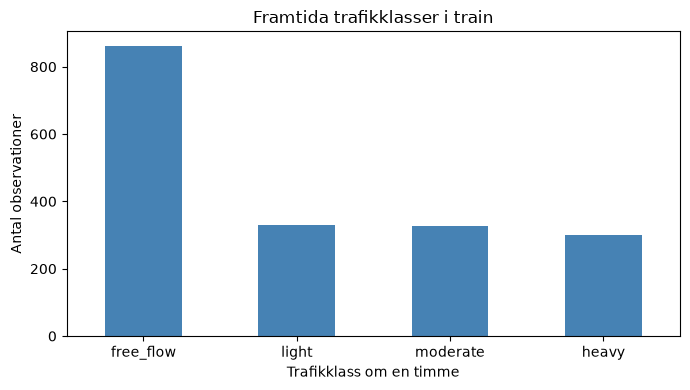

In [23]:
train_class_counts = y_train.value_counts().reindex(class_order, fill_value=0)
train_class_counts.plot(kind="bar", color="steelblue", figsize=(7, 4))
plt.title("Framtida trafikklasser i train")
plt.xlabel("Trafikklass om en timme")
plt.ylabel("Antal observationer")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Preprocessing och utvärderingsmått

**Hur:** Jag skapar en pipeline för Logistic Regression och KNN med skalning och en för trädmodeller utan skalning. Jag skapar också en funktion som räknar flera mått.

**Varför:** Skalning är viktig för KNN och hjälper Logistic Regression. Pipeline lär sig medianer, kategorier och skalning från train, inte test. Flera mått behövs eftersom klasserna är olika vanliga.

**Resultat:** Cellen förbereder verktyg och ger ännu inga modellresultat.

**Kodförklaring:** `SimpleImputer` fyller saknade värden med median eller vanligaste kategori från träningen. `OneHotEncoder` gör om textfeatures till kolumner och hanterar okända testkategorier. `metrics()` sammanfattar förutsägelserna.


**Kodförklaring:**
- `numeric_scaled` fyller saknade tal med medianen och skalar dem för Logistic Regression och KNN.
- `numeric_tree` fyller saknade tal på samma sätt men skalar dem inte, eftersom träd inte behöver skalning.
- `categorical` fyller saknade kategorier med den vanligaste och gör om kategorierna till separata kolumner.
- `ColumnTransformer` väljer rätt behandling för numeriska respektive kategoriska features. `preprocess_scaled` används för Logistic Regression och KNN; `preprocess_tree` används för trädmodellerna.
- `metrics()` räknar utvärderingsmåtten för modellens förutsägelser. Alla ersättningsvärden och skalor lärs från train när modellen tränas.
  
- **Accuracy:** andelen rätt av alla gissningar.
- **Precision:** av de gånger modellen gissade en klass, hur många var rätt?
- **Recall:** av alla verkliga fall i en klass, hur många hittade modellen?
- **F1-score:** väger ihop precision och recall.
- **Balanced accuracy:** genomsnittlig recall för klasserna som finns i facit.
- **Confusion matrix:** visar vilka verkliga klasser som förväxlas med vilka gissningar.
- `macro` betyder att varje klass får lika stor vikt i medelvärdet. Klassrapporten visar även `support`, antal verkliga observationer per klass.

In [24]:
numeric_scaled = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler()),])

In [25]:
numeric_tree = Pipeline([("imputer", SimpleImputer(strategy="median")),])

In [26]:
categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("onehot", OneHotEncoder(handle_unknown="ignore")),])

In [27]:
preprocess_scaled = ColumnTransformer([("numeric", numeric_scaled, make_column_selector(dtype_include="number")),
                                       ("categorical", categorical, make_column_selector(dtype_exclude="number")),])

In [28]:
preprocess_tree = ColumnTransformer([("numeric", numeric_tree, make_column_selector(dtype_include="number")),
                                     ("categorical", categorical, make_column_selector(dtype_exclude="number")),])

In [29]:
def metrics(y_true, prediction):
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "macro_precision": precision_score(y_true, prediction, labels=class_order, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, prediction, labels=class_order, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, prediction, labels=class_order, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
    }

## 3. Två baselines

**Hur:** jag tränar en `DummyClassifier` på train. Den andra baselinen är persistens: den aktuella trafikklassen används som gissning för klassen om en timme.

**Varför:** En baseline är en enkel jämförelse som visar vad en mer avancerad modell bör förbättra. Persistens är relevant för trafik men kräver att aktuell klass är känd när prognosen görs.

**Resultat:** Dummy lärde sig att `free_flow` var vanligast i train. Mätvärdena för båda baselines visas i experimentet nedan. Att `free_flow` var 47,3 % i hela EDA-urvalet betyder inte att Dummy får 47,3 % accuracy på test.

**Kodförklaring:** `strategy="most_frequent"` väljer den vanligaste klassen från `y_train`. `fit()` tränar regeln; persistens behöver ingen träning.


In [32]:
# Baseline 1: vanligaste framtida klassen i train.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
print("Dummys klass:", dummy.classes_[dummy.class_prior_.argmax()])

# Baseline 2: nuvarande klass används senare som persistensgissning.

Dummys klass: free_flow


## 4. Träna featuregrupper A, B och C

**Hur:** Jag tränar samma Logistic Regression med var och en av de tre förutbestämda featuregrupperna.

**Varför:** Jag undersöker om trafikvolymer och aktuella mätvärden tillför information jämfört med tid, väder och vägtyp. Aktuell hastighet och beläggning kan användas bara om de är tillgängliga när prognosen görs.

**Resultat:** Tre modeller tränas. Gruppjämförelsen visas senare på test; ingen grupp väljs utifrån testet innan övriga modeller tränas.

**Kodförklaring:** `clone()` ger varje modell egen preprocessing. `fit()` lär modellen från de angivna kolumnerna och `y_train`.


In [33]:
# Algoritm: Logistic Regression med tre olika featuregrupper.
logistic_a = Pipeline([
    ("preprocess", clone(preprocess_scaled)),
    ("model", LogisticRegression(max_iter=2000)),
])
logistic_b = clone(logistic_a)
logistic_c = clone(logistic_a)

logistic_a.fit(X_train[features_a], y_train)
logistic_b.fit(X_train[features_b], y_train)
logistic_c.fit(X_train[features_c], y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['free_flow','heavy','light','moderate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['hour','day_of_week','weather_condition',...,'truck_count_15min', 'avg_speed_kmh','occupancy_rate']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropp

## 5. Träna fyra algoritmer och förutbestämda trädvarianter

**Hur:** Här jämföras Logistic Regression från grupp C med Decision Tree, Random Forest och KNN på samma grupp. Dessutom tränar vi Decision Tree med djup 3, 5 och 10 samt djup 10 med klassvikter.

**Varför:** Först jämför vi olika algoritmer. Därefter visar trädvarianterna hur en parameter och klassvikter påverkar resultatet. Vi försöker välja den enklaste modellen som ger tillräckligt bra resultat, inte automatiskt den mest komplexa.

**Resultat:** Samtliga modeller tränas utan att använda testresultat. Djupen och klassvikterna är exempel som bestäms före jämförelsen; resultaten och ett eventuellt modellval är experimentella.

**Kodförklaring:** `max_depth` begränsar trädets djup och `min_samples_leaf` minsta antal träningsrader i ett blad. Random Forest använder flera träd. KNN låter fem närliggande träningsexempel rösta. `class_weight="balanced"` ger mindre vanliga klasser högre vikt under träningen. `random_state=42` gör slumpbaserade delar reproducerbara.

Klassviktsjämförelsen gäller här ett **beslutsträd**, inte en modell som valts efter testresultatet. KNN har ingen `class_weight`-parameter. KNN:s `weights="distance"` viktar avstånd, inte klassernas förekomst.

In [35]:
features = features_c
# Algoritm: Decision Tree Classifier, begränsat träd.
tree = Pipeline([("preprocess", clone(preprocess_tree)),("model", DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)),])


In [36]:
# Algoritm: Random Forest Classifier, flera träd som röstar.
forest = Pipeline([("preprocess", clone(preprocess_tree)),("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1)),])

In [37]:
# Algoritm: K-Nearest Neighbors, fem närmaste grannar.
knn = Pipeline([("preprocess", clone(preprocess_scaled)),("model", KNeighborsClassifier(n_neighbors=5)),])

In [38]:
# Samma Decision Tree med andra djup och klassvikter.
tree_3 = clone(tree).set_params(model__max_depth=3)
tree_10 = clone(tree).set_params(model__max_depth=10)
tree_10_balanced = clone(tree_10).set_params(model__class_weight="balanced")

tree.fit(X_train[features], y_train)
forest.fit(X_train[features], y_train)
knn.fit(X_train[features], y_train)
tree_3.fit(X_train[features], y_train)
tree_10.fit(X_train[features], y_train)
tree_10_balanced.fit(X_train[features], y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['free_flow','heavy','light','moderate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['hour','day_of_week','weather_condition',...,'truck_count_15min', 'avg_speed_kmh','occupancy_rate']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropp

## 6. Förbered en separat varning om samma tidpunkt

**Hur:** Den tränar två små beslutsträd med endast aktuell `occupancy_rate`: ett mot aktuell klass och ett mot klassen en timme senare.

**Varför:** Aktuell beläggning kan vara nära kopplad till hur den aktuella trafikklassen definieras. Det första trädet visar därför en annan, facitnära uppgift och är **inte** en giltig framtidsprognos.

**Resultat:** Träden tränas på train; deras resultat visas separat i experimentet och ingår inte i modellvalet.

**Kodförklaring:** Modellerna har samma feature och inställningar. Skillnaden är att den ena lär sig `congestion_level`, medan den andra lär sig `future_congestion_level`.

In [39]:
# Algoritm: Decision Tree Classifier för två olika mål.
same_time_tree = DecisionTreeClassifier(max_depth=5, random_state=42)
future_tree = DecisionTreeClassifier(max_depth=5, random_state=42)

same_time_tree.fit(train[["occupancy_rate"]], train["congestion_level"])
future_tree.fit(train[["occupancy_rate"]], y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

## 7. Predict: en gemensam testomgång

**Hur:** Alla förutbestämda modeller och baselines gör sina förutsägelser på samma testperiod. Vi sparar förutsägelserna för tabeller och grafer nedan.

**Varför:** Samma testrader gör jämförelsen rättvis. Alla inställningar var bestämda innan testresultaten visades.

**Resultat:** Förutsägelserna skapas men inga mätvärden visas ännu. Följande celler analyserar samma testomgång, inte nya försök.

**Kodförklaring:** `predict()` använder varje färdigtränad modell. Persistens använder direkt `congestion_level` från början av varje testpar. Nycklarna i `predictions` gör det lätt att återanvända samma förutsägelser.

In [40]:
predictions = {
    "Dummy": dummy.predict(X_test),
    "Persistens": test["congestion_level"],
    "Logistic A": logistic_a.predict(X_test[features_a]),
    "Logistic B": logistic_b.predict(X_test[features_b]),
    "Logistic C": logistic_c.predict(X_test[features_c]),
    "Decision Tree": tree.predict(X_test[features]),
    "Random Forest": forest.predict(X_test[features]),
    "KNN": knn.predict(X_test[features]),
    "Tree djup 3": tree_3.predict(X_test[features]),
    "Tree djup 10": tree_10.predict(X_test[features]),
    "Tree djup 10 balanced": tree_10_balanced.predict(X_test[features]),
}
same_time_prediction = same_time_tree.predict(test[["occupancy_rate"]])
future_prediction = future_tree.predict(test[["occupancy_rate"]])

## 8. Utvärdera baselines och featuregrupper

**Hur:** Vi visar accuracy, macro precision, macro recall, macro F1 och balanced accuracy för båda baselines och Logistic Regression med A, B och C.

**Varför:** Jämförelsen visar både vad enkla gissningsregler klarar och om fler features verkar hjälpa i detta experiment. Accuracy ensam kan dölja dåliga resultat för enskilda klasser.

**Resultat:** I referenskörningen fick Dummy accuracy 0,470 och macro F1 0,160, medan persistens fick 0,650 respektive 0,555. Logistic Regression med A, B och C fick macro F1 0,381, 0,510 och 0,526: tilläggen förbättrade resultatet stegvis men ingen av de tre slog persistens på macro F1.

**Kodförklaring:** `metrics()` jämför samma `y_test` med varje sparad förutsägelse. `DataFrame` visar resultaten sida vid sida.


In [41]:
# Utvärdering: Accuracy, Precision, Recall, F1-score och Balanced Accuracy.
feature_results = pd.DataFrame([
    {"modell": "Dummy", **metrics(y_test, predictions["Dummy"])},
    {"modell": "Persistens", **metrics(y_test, predictions["Persistens"])},
    {"modell": "Logistic A", **metrics(y_test, predictions["Logistic A"])},
    {"modell": "Logistic B", **metrics(y_test, predictions["Logistic B"])},
    {"modell": "Logistic C", **metrics(y_test, predictions["Logistic C"])},
])
display(feature_results.round(3))

print("Dummy – klassrapport")
print(classification_report(y_test, predictions["Dummy"], labels=class_order, zero_division=0))
print("Persistens – klassrapport")
print(classification_report(y_test, predictions["Persistens"], labels=class_order, zero_division=0))

,modell,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy
0,Dummy,0.470,0.118,0.250,0.160,0.250
1,Persistens,0.650,0.558,0.553,0.555,0.553
2,Logistic A,0.636,0.398,0.468,0.381,0.468
3,Logistic B,0.672,0.561,0.536,0.510,0.536
4,Logistic C,0.683,0.543,0.554,0.526,0.554


Dummy – klassrapport
              precision    recall  f1-score   support

   free_flow       0.47      1.00      0.64       212
       light       0.00      0.00      0.00        74
    moderate       0.00      0.00      0.00        89
       heavy       0.00      0.00      0.00        76

    accuracy                           0.47       451
   macro avg       0.12      0.25      0.16       451
weighted avg       0.22      0.47      0.30       451

Persistens – klassrapport
              precision    recall  f1-score   support

   free_flow       0.84      0.86      0.85       212
       light       0.17      0.18      0.17        74
    moderate       0.67      0.66      0.67        89
       heavy       0.55      0.51      0.53        76

    accuracy                           0.65       451
   macro avg       0.56      0.55      0.56       451
weighted avg       0.65      0.65      0.65       451



### Graf: baselines och featuregrupper

**Hur:** Vi visar macro F1 för båda baselines och de tre featuregrupperna.

**Varför:** Grafen gör det lätt att se om fler features förbättrar Logistic Regression och om modellerna slår de enkla gissningsreglerna.

**Resultat:** I referenskörningen ökade macro F1 från 0,381 för A till 0,526 för C, men persistens hade 0,555. Jämför med era egna värden.

**Kodförklaring:** `plt.bar()` använder modellnamnen och `macro_f1` från tabellen. Multiplikation med 100 visar värdet i procent och `bar_label()` skriver det ovanför stapeln.

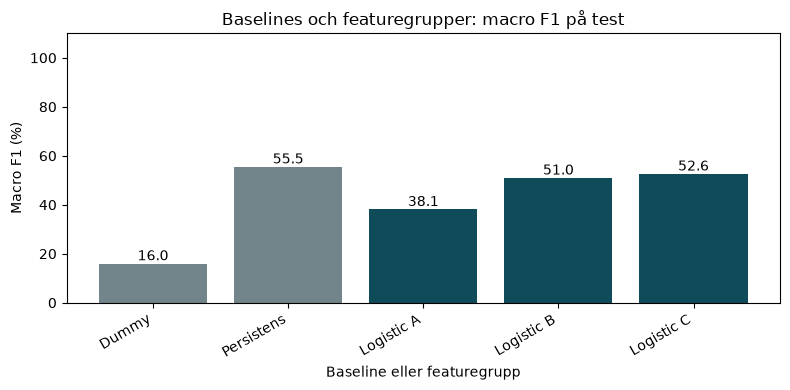

In [42]:
plt.figure(figsize=(8, 4))
bars = plt.bar(
    feature_results["modell"], feature_results["macro_f1"] * 100,
    color=["#71858a", "#71858a", "#104b5a", "#104b5a", "#104b5a"],
)
plt.bar_label(bars, fmt="%.1f")
plt.title("Baselines och featuregrupper: macro F1 på test")
plt.xlabel("Baseline eller featuregrupp")
plt.ylabel("Macro F1 (%)")
plt.ylim(0, 110)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 9. Varning: samma rad är inte en framtidsprognos

**Hur:** Den jämför accuracy för den aktuella klassen med accuracy för klassen en timme senare, från de två separata träden.

**Varför:** Att förutsäga en klass från samtidiga mätningar är inte samma uppgift som att förutsäga framtiden. En nästan perfekt siffra för den aktuella klassen kan vara facitnära och får inte rapporteras som framtidsprestanda.

**Resultat:** Trädet med samma tids target fick accuracy 1,000 och framtidsträdet 0,701% i referenskörningen. Jämförelsen illustrerar skillnaden mellan uppgifterna; 1,000 är inte ett resultat för framtidsprognosen.

**Kodförklaring:** Första `accuracy_score()` jämför med aktuell klass och den andra med den framtida klassen, `y_test`.


In [43]:
# Utvärdering: Accuracy för två olika uppgifter.
print("Samma tid – inte framtidsprognos:",
      round(accuracy_score(test["congestion_level"], same_time_prediction), 3))
print("En timme framåt:",
      round(accuracy_score(y_test, future_prediction), 3))

Samma tid – inte framtidsprognos: 1.0
En timme framåt: 0.701


### Graf: två olika mål

**Hur:** Här visar de två uppgifternas accuracy bredvid varandra.

**Varför:** Grafen tydliggör att en hög siffra för samtida klass inte är samma sak som en lyckad framtidsprognos.

**Resultat:** Referenskörningen gav 1,000 för samtida klass och 0,701 för framtida klass. Staplarna gäller olika facit och ska inte användas för att välja framtidsmodell.

**Kodförklaring:** `accuracy_score()` jämför varje träds förutsägelser med sitt eget facit. Grafen visar värdena i procent; den orange stapeln markerar uppgiften som inte är en framtidsprognos.

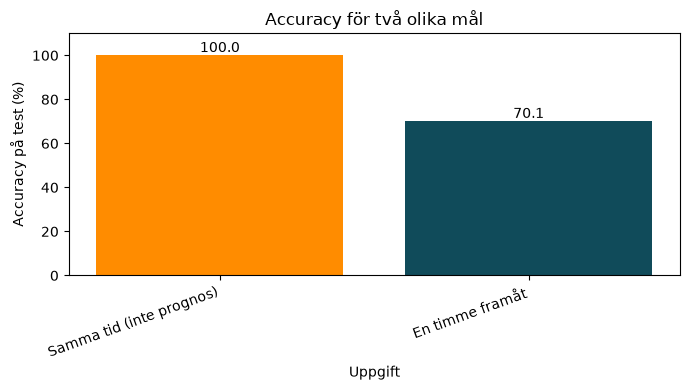

In [44]:
time_results = pd.Series({
    "Samma tid (inte prognos)": accuracy_score(test["congestion_level"], same_time_prediction),
    "En timme framåt": accuracy_score(y_test, future_prediction),
})
plt.figure(figsize=(7, 4))
bars = plt.bar(time_results.index, time_results.values * 100, color=["darkorange", "#104b5a"])
plt.bar_label(bars, fmt="%.1f")
plt.title("Accuracy för två olika mål")
plt.xlabel("Uppgift")
plt.ylabel("Accuracy på test (%)")
plt.ylim(0, 110)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 10. Jämför och utvärdera de fyra algoritmerna

**Hur:** Här visar samma mått för Logistic Regression, Decision Tree, Random Forest och KNN med grupp C.

**Varför:** Alla fyra använder samma ingångar och testperiod. Jämför både med varandra och med baselines, och väg förbättring mot komplexitet.

**Resultat:** I referenskörningen fick Logistic Regression, Decision Tree, Random Forest och KNN macro F1 0,526, 0,756, 0,754 respektive 0,580. Det begränsade trädet och skogen slog båda persistensens 0,555. Trädet är enklare att förklara än skogen och hade liknande macro F1, men klassrapporterna visar också skillnader mellan klasserna.

**Kodförklaring:** Tabellen återanvänder förutsägelserna från testomgången. Den tränar inga nya modeller och ändrar inga inställningar.


In [46]:
# Utvärdering: Accuracy, Precision, Recall, F1-score och Balanced Accuracy.
model_results = pd.DataFrame([
    {"modell": "Dummy", **metrics(y_test, predictions["Dummy"])},
    {"modell": "Persistens", **metrics(y_test, predictions["Persistens"])},
    {"modell": "Logistic Regression", **metrics(y_test, predictions["Logistic C"])},
    {"modell": "Decision Tree", **metrics(y_test, predictions["Decision Tree"])},
    {"modell": "Random Forest", **metrics(y_test, predictions["Random Forest"])},
    {"modell": "KNN", **metrics(y_test, predictions["KNN"])},
])
display(model_results.round(3))

,modell,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy
0,Dummy,0.470,0.118,0.250,0.160,0.250
1,Persistens,0.650,0.558,0.553,0.555,0.553
2,Logistic Regression,0.683,0.543,0.554,0.526,0.554
3,Decision Tree,0.812,0.762,0.756,0.756,0.756
4,Random Forest,0.818,0.791,0.751,0.754,0.751
5,KNN,0.681,0.598,0.576,0.580,0.576


### Graf: algoritmer och baselines

**Hur:** Här visar två separata stapeldiagram för accuracy och macro F1 för de fyra algoritmerna och båda baselines.

**Varför:** Accuracy visar andelen rätt totalt, medan macro F1 ger varje klass lika vikt. De två måtten tillsammans ger en bättre jämförelse än accuracy ensam.

**Resultat:** I referenskörningen hade Decision Tree och Random Forest högre macro F1 än båda baselines. Se även klassrapporterna och matriserna innan ni sammanfattar skillnaderna.

**Kodförklaring:** `model_results` är tabellen från föregående cell. Liksom i presentationens exempel visar vi ett mått per graf och skriver värdet ovanför varje stapel. Båda graferna använder procent för att vara enkla att jämföra.


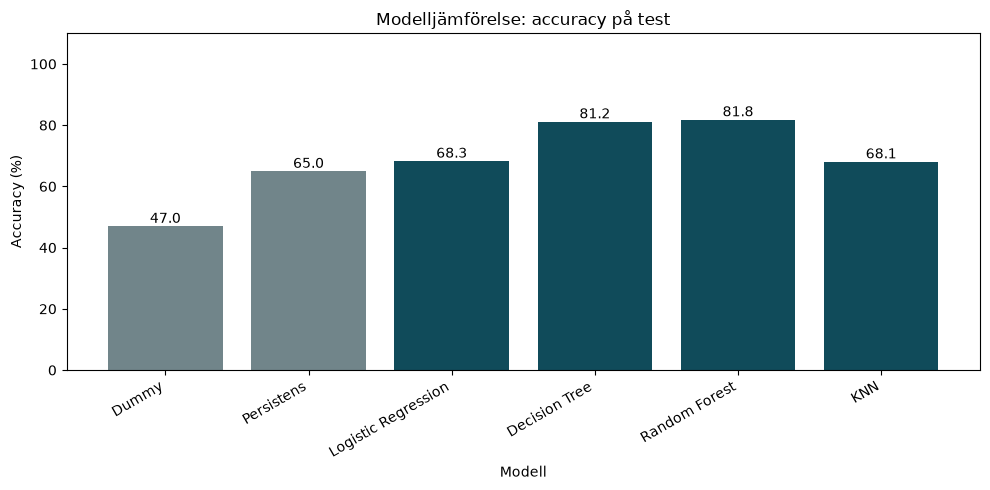

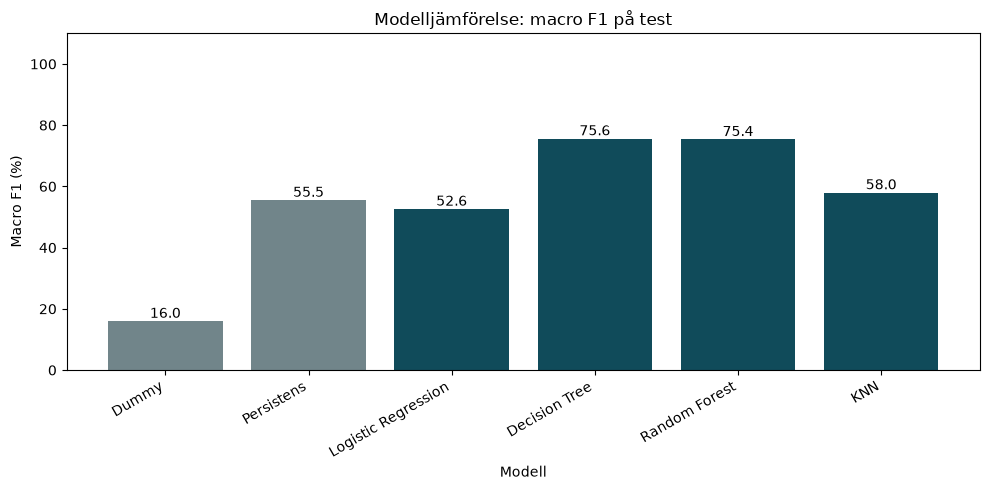

In [47]:
colors = ["#71858a", "#71858a", "#104b5a", "#104b5a", "#104b5a", "#104b5a"]

plt.figure(figsize=(10, 5))
bars = plt.bar(model_results["modell"], model_results["accuracy"] * 100, color=colors)
plt.bar_label(bars, fmt="%.1f")
plt.title("Modelljämförelse: accuracy på test")
plt.xlabel("Modell")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 110)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
bars = plt.bar(model_results["modell"], model_results["macro_f1"] * 100, color=colors)
plt.bar_label(bars, fmt="%.1f")
plt.title("Modelljämförelse: macro F1 på test")
plt.xlabel("Modell")
plt.ylabel("Macro F1 (%)")
plt.ylim(0, 110)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 11. Klassrapporter och confusion matrix

**Hur:** Visar precision, recall och F1-score per klass samt en confusion matrix för var och en av de fyra algoritmerna.

**Varför:** Genomsnitt kan dölja att en modell missar `heavy` eller förväxlar andra klasser. Rapporterna och graferna visar vilka fel som görs.

**Resultat:** I referenskörningen hade Decision Tree recall 0,78 för `heavy` och 0,59 för `light`; Random Forest hade 0,84 respektive 0,39. Skogen hittade alltså fler `heavy`, men färre `light`. Studera även de andra klassernas resultat och antal (`support`).

**Kodförklaring:** I matrisen är raderna verkliga klasser och kolumnerna förutsagda klasser. `normalize="true"` visar andelar inom varje verklig klass.


In [50]:
algorithms = [("Logistic Regression", "Logistic C"),("Decision Tree", "Decision Tree"),("Random Forest", "Random Forest"),("KNN", "KNN"),]

Logistic Regression
              precision    recall  f1-score   support

   free_flow       0.79      0.95      0.86       212
       light       0.29      0.08      0.13        74
    moderate       0.61      0.83      0.70        89
       heavy       0.48      0.36      0.41        76

    accuracy                           0.68       451
   macro avg       0.54      0.55      0.53       451
weighted avg       0.62      0.68      0.64       451



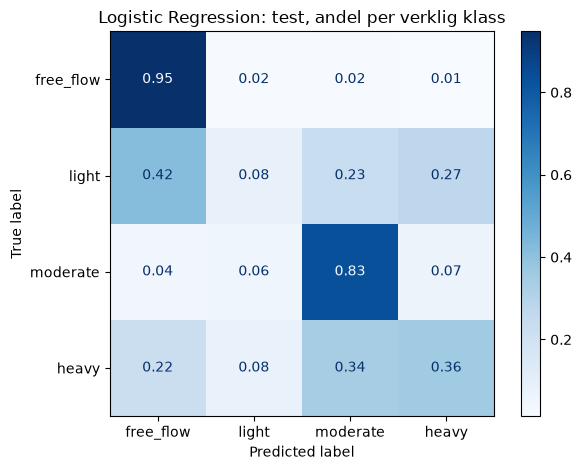

Decision Tree
              precision    recall  f1-score   support

   free_flow       0.94      0.94      0.94       212
       light       0.75      0.59      0.66        74
    moderate       0.67      0.71      0.69        89
       heavy       0.69      0.78      0.73        76

    accuracy                           0.81       451
   macro avg       0.76      0.76      0.76       451
weighted avg       0.81      0.81      0.81       451



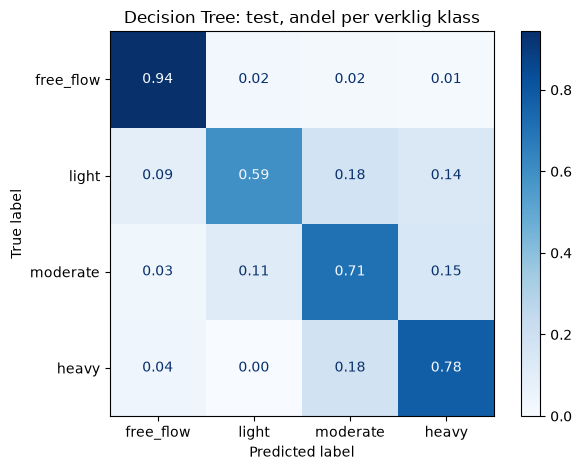

Random Forest
              precision    recall  f1-score   support

   free_flow       0.88      0.96      0.92       212
       light       0.78      0.39      0.52        74
    moderate       0.73      0.81      0.77        89
       heavy       0.77      0.84      0.81        76

    accuracy                           0.82       451
   macro avg       0.79      0.75      0.75       451
weighted avg       0.82      0.82      0.80       451



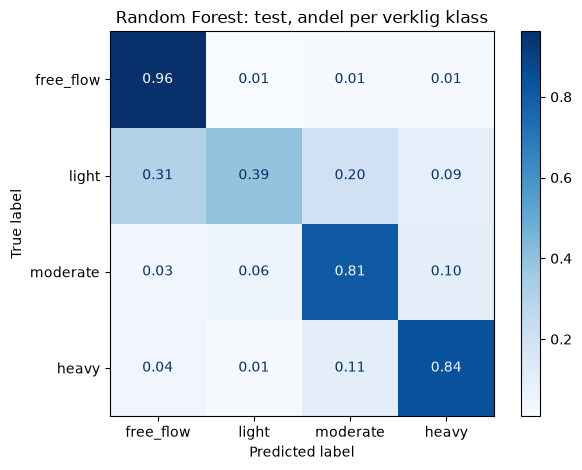

KNN
              precision    recall  f1-score   support

   free_flow       0.77      0.92      0.84       212
       light       0.39      0.23      0.29        74
    moderate       0.70      0.62      0.65        89
       heavy       0.54      0.54      0.54        76

    accuracy                           0.68       451
   macro avg       0.60      0.58      0.58       451
weighted avg       0.65      0.68      0.66       451



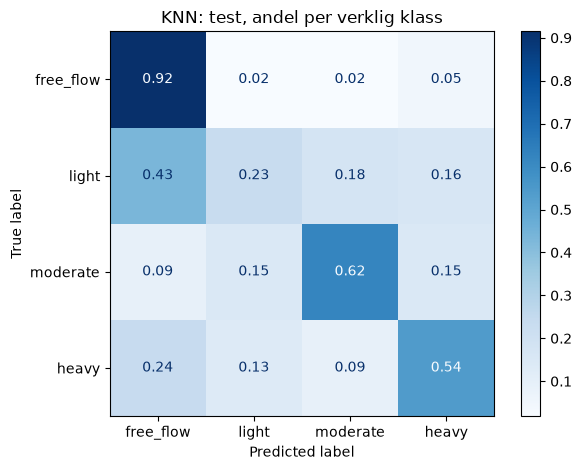

In [51]:
# Utvärdering: Precision, Recall, F1-score och Confusion Matrix.
for name, key in algorithms:
    print(name)
    print(classification_report(y_test, predictions[key], labels=class_order, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[key],
        labels=class_order, display_labels=class_order,
        normalize="true", values_format=".2f", cmap="Blues",
    )
    plt.title(f"{name}: test, andel per verklig klass")
    plt.tight_layout()
    plt.show()

## 12. Jämför träddjup och klassvikter

**Hur:** Den jämför djup 3, 5 och 10 för trädet, och sedan djup 10 med och utan `balanced`.

**Varför:** Djupjämförelsen ändrar bara `max_depth`; klassviktsjämförelsen ändrar bara `class_weight`. Grafen och klassrapporterna hjälper oss att förklara resultaten och eventuella kompromisser.

**Resultat:** Referenskörningen gav macro F1 0,633, 0,756 och 0,805 för djup 3, 5 och 10. För djup 10 sjönk `heavy`-recall från 0,83 utan vikter till 0,78 med vikter, medan `light`-recall ökade från 0,70 till 0,74. Macro F1 sjönk från 0,805 till 0,791. Bäst på detta test är ett experimentellt resultat, inte bevis på bäst prestanda på ny data.

**Kodförklaring:** `depth_results` jämför de tre redan tränade träden. Grafen visar deras macro F1. De två rapporterna jämför samma djup och visar recall för varje klass.

In [52]:
# Algoritm: Decision Tree Classifier med ett max_depth i taget.
# Utvärdering: Accuracy, Precision, Recall, F1-score och Balanced Accuracy.
depth_results = pd.DataFrame([
    {"max_depth": 3, **metrics(y_test, predictions["Tree djup 3"])},
    {"max_depth": 5, **metrics(y_test, predictions["Decision Tree"])},
    {"max_depth": 10, **metrics(y_test, predictions["Tree djup 10"])},
])
display(depth_results.round(3))

,max_depth,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy
0,3,0.734,0.668,0.662,0.633,0.662
1,5,0.812,0.762,0.756,0.756,0.756
2,10,0.847,0.810,0.802,0.805,0.802


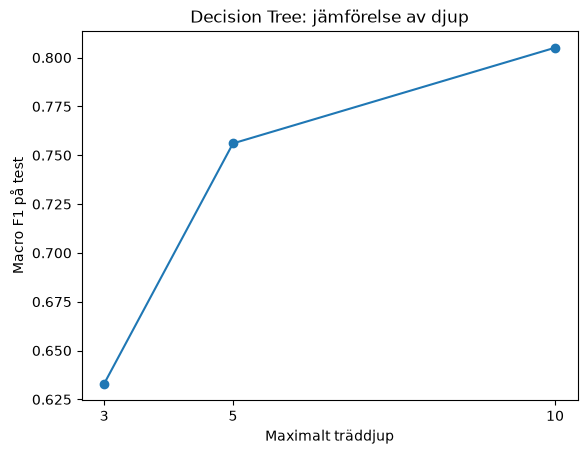

In [53]:
depth_results.plot(x="max_depth", y="macro_f1", marker="o", legend=False)
plt.xticks([3, 5, 10])
plt.xlabel("Maximalt träddjup")
plt.ylabel("Macro F1 på test")
plt.title("Decision Tree: jämförelse av djup")
plt.show()

In [54]:
# Utvärdering: klassvikternas effekt på Precision, Recall och F1-score.
print("Djup 10 utan klassvikter")
print(classification_report(y_test, predictions["Tree djup 10"], labels=class_order, zero_division=0))
print("Djup 10 med balanced")
print(classification_report(y_test, predictions["Tree djup 10 balanced"], labels=class_order, zero_division=0))
display(pd.DataFrame([
    {"modell": "Utan vikter", **metrics(y_test, predictions["Tree djup 10"])},
    {"modell": "Balanced", **metrics(y_test, predictions["Tree djup 10 balanced"])},
]).round(3))

Djup 10 utan klassvikter
              precision    recall  f1-score   support

   free_flow       0.94      0.96      0.95       212
       light       0.80      0.70      0.75        74
    moderate       0.73      0.72      0.72        89
       heavy       0.78      0.83      0.80        76

    accuracy                           0.85       451
   macro avg       0.81      0.80      0.81       451
weighted avg       0.85      0.85      0.85       451

Djup 10 med balanced
              precision    recall  f1-score   support

   free_flow       0.96      0.93      0.94       212
       light       0.73      0.74      0.74        74
    moderate       0.68      0.73      0.71        89
       heavy       0.78      0.78      0.78        76

    accuracy                           0.83       451
   macro avg       0.79      0.79      0.79       451
weighted avg       0.84      0.83      0.84       451



,modell,accuracy,macro_precision,macro_recall,macro_f1,balanced_accuracy
0,Utan vikter,0.847,0.810,0.802,0.805,0.802
1,Balanced,0.834,0.789,0.795,0.791,0.795


### Graf: recall med och utan klassvikter

**Hur:** Den visar recall för varje klass med och utan `balanced`, för samma träddjup.

**Varför:** Grafen visar om modellen hittar fler `heavy` och om någon annan klass samtidigt påverkas.

**Resultat:** I referenskörningen sjönk `heavy`-recall från 0,83 till 0,78 med vikter, medan `light`-recall ökade från 0,70 till 0,74. Effekten är alltså olika för olika klasser.

**Kodförklaring:** `average=None` ger ett recall-värde per klass i `class_order`. Varje klass får två staplar, en för varje inställning.


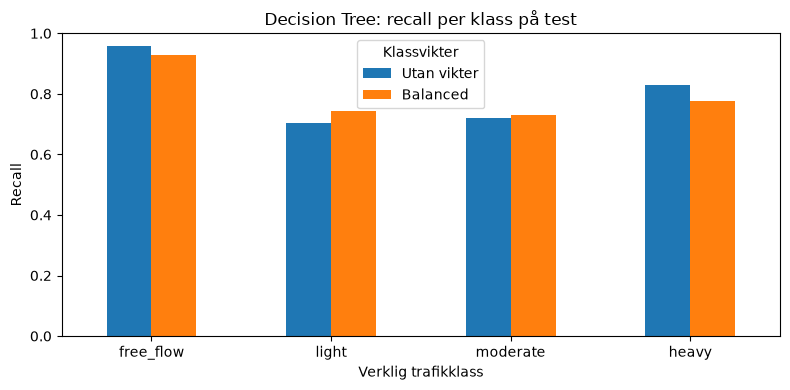

In [55]:
class_recall = pd.DataFrame({
    "Utan vikter": recall_score(
        y_test, predictions["Tree djup 10"], labels=class_order, average=None, zero_division=0
    ),
    "Balanced": recall_score(
        y_test, predictions["Tree djup 10 balanced"], labels=class_order, average=None, zero_division=0
    ),
}, index=class_order)

class_recall.plot(kind="bar", figsize=(8, 4))
plt.title("Decision Tree: recall per klass på test")
plt.xlabel("Verklig trafikklass")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Klassvikter")
plt.tight_layout()
plt.show()

## 13. Slutsatsen
**Mål och metod:** Vi förutsade trafikklassen **en timme framåt**, tränade på äldre data och testade på senare data. Preprocessing lärdes enbart från train. Aktuell hastighet och beläggning kan användas om de är kända vid prognostillfället.

**Baselines och features:** Dummy fick **47,0 % accuracy och 0,160 macro F1**, medan persistens fick **65,0 % och 0,555**. För Logistic Regression steg macro F1 från **0,381 för grupp A** till **0,526 för C**, men ingen av grupperna slog persistens på detta mått.

**Modeller:** Decision Tree med djup 5 fick **0,756 macro F1**, ungefär som Random Forests **0,754**, men är enklare att förklara. Trädet med djup 10 fick **84,7 % accuracy och 0,805 macro F1**; förbättringen måste vägas mot ökad komplexitet och risk för överanpassning.

**Klassvikter:** För djup 10 sjönk `heavy`-recall från **0,83 till 0,78** med `balanced`, medan `light`-recall ökade från **0,70 till 0,74**. Klassvikter förbättrade alltså inte alla klasser. Klassrapporter och confusion matrix behövs för att förstå sådana skillnader.

**Begränsningar:** Resultaten är **experimentella** eftersom samma testperiod användes för jämförelse och modellval och redan tidigare hade undersökts. En oberoende slututvärdering kräver ny framtida data. Urvalet omfattar bara fall där nästa registrerade mätning är exakt en timme senare; det testar inte generalisering till nya sensorer. Dubbletter i originaldatan behöver också undersökas.

**Vad har vi lärt oss?** Trafik en timme framåt är svårare att förutsäga än trafikklassen just nu. Decision Tree gav bra resultat jämfört med båda baselines och var enklare att förklara än Random Forest. Klassvikter förbättrade inte alla klasser, så vi behöver titta på mer än accuracy.